In [1]:

# STEP 1: INSPECT ECOMMERCE BEHAVIOR DATASET

from pathlib import Path
import duckdb
import pandas as pd

# Locate our eCommerce Behavior folder
data_folder = (
    Path.home()
    / "Desktop"
    / "supply-chain-portfolio"
    / "kaggle-raw-data"
    / "ecommerce-behavior"
)

# Identify the two CSV files
oct_file = data_folder / "2019-Oct.csv"
nov_file = data_folder / "2019-Nov.csv"

# Verify file locations and sizes
print("===== DATASET INVENTORY =====")

for file in [oct_file, nov_file]:
    print("File:", file.name)
    print("Found:", file.is_file())

    if file.is_file():
        print(
            "Size (GB):",
            round(file.stat().st_size / 1_000_000_000, 2)
        )

    print()

# Stop if the October file cannot be found
assert oct_file.is_file(), "October CSV not found"

# Connect to DuckDB
db = duckdb.connect()

# Read only a small preview from October
sample = db.execute("""
    SELECT *
    FROM read_csv(
        ?,
        all_varchar = true,
        sample_size = 10000
    )
    LIMIT 5
""", [str(oct_file)]).df()

# Display the columns
print("===== DATASET COLUMNS =====")
print(sample.columns.tolist())

# Display five example records
print("\n===== FIRST FIVE RECORDS =====")
display(sample)

print("\nColumns identified:", len(sample.columns))


===== DATASET INVENTORY =====
File: 2019-Oct.csv
Found: True
Size (GB): 5.67

File: 2019-Nov.csv
Found: True
Size (GB): 9.01

===== DATASET COLUMNS =====
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

===== FIRST FIVE RECORDS =====


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d



Columns identified: 9


In [2]:

# STEP 2: IDENTIFY CUSTOMER EVENT TYPES


# Analyze the first 100,000 October event records
event_summary = db.execute("""
    WITH sampled_events AS (
        SELECT
            event_time,
            event_type
        FROM read_csv(
            ?,
            all_varchar = true,
            sample_size = 10000
        )
        LIMIT 100000
    )

    SELECT
        event_type AS Event_Type,

        COUNT(*) AS Event_Count,

        ROUND(
            COUNT(*) * 100.0 /
            SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage

    FROM sampled_events

    GROUP BY event_type
    ORDER BY Event_Count DESC
""", [str(oct_file)]).df()

print("===== CUSTOMER EVENT TYPE SUMMARY =====")
display(event_summary)

print("\nTotal records inspected:")
print(event_summary["Event_Count"].sum())


===== CUSTOMER EVENT TYPE SUMMARY =====


,Event_Type,Event_Count,Percentage
0,view,97130,97.13
1,purchase,1655,1.66
2,cart,1215,1.22



Total records inspected:
100000


In [3]:
# STEP 3: EXPLORE ELECTRONICS CATEGORIES AND BRANDS

# Create a temporary DuckDB table from 100,000 records
db.execute("""
    CREATE OR REPLACE TEMP TABLE ecommerce_sample AS
    SELECT
        event_type,
        category_code,
        brand
    FROM read_csv(
        ?,
        all_varchar = true,
        sample_size = 10000
    )
    LIMIT 100000
""", [str(oct_file)])

# Analyze the most common electronics categories
electronics_categories = db.execute("""
    SELECT
        category_code AS Category,

        COUNT(*) AS Total_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS Views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS Cart_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS Purchases

    FROM ecommerce_sample

    WHERE category_code LIKE 'electronics.%'

    GROUP BY category_code

    ORDER BY Total_Events DESC

    LIMIT 10
""").df()

print("===== TOP 10 ELECTRONICS CATEGORIES =====")
display(electronics_categories)

# Identify the most common electronics brands
electronics_brands = db.execute("""
    SELECT
        brand AS Brand,
        COUNT(*) AS Total_Events

    FROM ecommerce_sample

    WHERE category_code LIKE 'electronics.%'
      AND brand IS NOT NULL

    GROUP BY brand

    ORDER BY Total_Events DESC

    LIMIT 10
""").df()

print("\n===== TOP 10 ELECTRONICS BRANDS =====")
display(electronics_brands)


===== TOP 10 ELECTRONICS CATEGORIES =====


,Category,Total_Events,Views,Cart_Events,Purchases
0,electronics.smartphone,26738,25113,867,758
1,electronics.clocks,3150,3085,30,35
2,electronics.audio.headphone,2609,2462,80,67
3,electronics.video.tv,1993,1918,34,41
4,electronics.telephone,773,758,5,10
5,electronics.audio.subwoofer,669,663,0,6
6,electronics.tablet,544,536,4,4
7,electronics.audio.acoustic,173,169,2,2
8,electronics.camera.video,105,104,0,1
9,electronics.audio.music_tools.piano,62,61,0,1



===== TOP 10 ELECTRONICS BRANDS =====


,Brand,Total_Events
0,samsung,10175
1,apple,9314
2,xiaomi,5597
3,huawei,2651
4,oppo,779
5,casio,608
6,nokia,584
7,sony,535
8,vivo,503
9,meizu,382


In [4]:
# STEP 4: INVESTIGATE HEADPHONE BRANDS AND DEMAND

# Analyze customer behavior by headphone brand
headphone_brands = db.execute("""
    SELECT
        COALESCE(brand, 'Unknown') AS Brand,

        COUNT(*) AS Total_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS Views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS Cart_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS Purchases

    FROM ecommerce_sample

    WHERE category_code = 'electronics.audio.headphone'

    GROUP BY Brand

    ORDER BY Total_Events DESC

    LIMIT 15
""").df()

print("===== TOP HEADPHONE BRANDS =====")
display(headphone_brands)


# Check specifically for Apple headphone activity
apple_headphones = db.execute("""
    SELECT
        event_type AS Event_Type,
        COUNT(*) AS Event_Count

    FROM ecommerce_sample

    WHERE category_code = 'electronics.audio.headphone'
      AND LOWER(brand) = 'apple'

    GROUP BY event_type

    ORDER BY Event_Count DESC
""").df()

print("\n===== APPLE HEADPHONE ACTIVITY =====")

if apple_headphones.empty:
    print(
        "No Apple headphone events found "
        "in this initial sample."
    )
else:
    display(apple_headphones)


# Summarize total headphone activity
headphone_summary = db.execute("""
    SELECT
        COUNT(*) AS Total_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS Views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS Cart_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS Purchases

    FROM ecommerce_sample

    WHERE category_code = 'electronics.audio.headphone'
""").df()

print("\n===== HEADPHONE CATEGORY SUMMARY =====")
display(headphone_summary)


===== TOP HEADPHONE BRANDS =====


,Brand,Total_Events,Views,Cart_Events,Purchases
0,apple,811,727,48,36
1,xiaomi,544,506,22,16
2,samsung,234,223,8,3
3,jbl,225,219,1,5
4,elari,134,133,0,1
5,sony,115,114,0,1
6,huawei,65,64,0,1
7,harper,62,62,0,0
8,awei,31,31,0,0
9,plantronics,30,30,0,0



===== APPLE HEADPHONE ACTIVITY =====


,Event_Type,Event_Count
0,view,727
1,cart,48
2,purchase,36



===== HEADPHONE CATEGORY SUMMARY =====


,Total_Events,Views,Cart_Events,Purchases
0,2609,2462,80,67


In [5]:

# STEP 5: FULL OCTOBER APPLE HEADPHONE ANALYSIS

# Analyze the complete October CSV using DuckDB
october_apple_daily = db.execute("""
    SELECT
        SUBSTR(event_time, 1, 10) AS Event_Date,

        COUNT(*) AS Total_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS Views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS Cart_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS Purchases,

        COUNT(DISTINCT product_id) AS Unique_Products

    FROM read_csv(
        ?,
        all_varchar = true,
        sample_size = 10000
    )

    WHERE category_code = 'electronics.audio.headphone'
      AND LOWER(TRIM(brand)) = 'apple'

    GROUP BY Event_Date
    ORDER BY Event_Date ASC
""", [str(oct_file)]).df()

print("===== FULL OCTOBER APPLE HEADPHONE ANALYSIS =====")

print("Days analyzed:", len(october_apple_daily))

print(
    "Total Apple headphone events:",
    october_apple_daily["Total_Events"].sum()
)

print(
    "Total product views:",
    october_apple_daily["Views"].sum()
)

print(
    "Total cart events:",
    october_apple_daily["Cart_Events"].sum()
)

print(
    "Total purchase events:",
    october_apple_daily["Purchases"].sum()
)

print("\n===== FIRST FIVE DAYS =====")
display(october_apple_daily.head())

print("\n===== LAST FIVE DAYS =====")
display(october_apple_daily.tail())


===== FULL OCTOBER APPLE HEADPHONE ANALYSIS =====
Days analyzed: 31
Total Apple headphone events: 397597
Total product views: 350331
Total cart events: 29782
Total purchase events: 17484

===== FIRST FIVE DAYS =====


,Event_Date,Total_Events,Views,Cart_Events,Purchases,Unique_Products
0,2019-10-01,11179,9878,757,544,11
1,2019-10-02,10962,9734,699,529,10
2,2019-10-03,11022,9786,705,531,12
3,2019-10-04,15699,13305,1655,739,12
4,2019-10-05,13619,11682,1379,558,11



===== LAST FIVE DAYS =====


,Event_Date,Total_Events,Views,Cart_Events,Purchases,Unique_Products
26,2019-10-27,11815,10330,948,537,13
27,2019-10-28,10343,9151,659,533,12
28,2019-10-29,10669,9577,628,464,11
29,2019-10-30,11834,10736,619,479,10
30,2019-10-31,12872,11772,657,443,10


In [6]:

# STEP 6: FULL NOVEMBER APPLE HEADPHONE ANALYSIS

# Analyze the complete November CSV using DuckDB
november_apple_daily = db.execute("""
    SELECT
        SUBSTR(event_time, 1, 10) AS Event_Date,

        COUNT(*) AS Total_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS Views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS Cart_Events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS Purchases,

        COUNT(DISTINCT product_id) AS Unique_Products

    FROM read_csv(
        ?,
        all_varchar = true,
        sample_size = 10000
    )

    WHERE category_code = 'electronics.audio.headphone'
      AND LOWER(TRIM(brand)) = 'apple'

    GROUP BY Event_Date
    ORDER BY Event_Date ASC
""", [str(nov_file)]).df()

print("===== FULL NOVEMBER APPLE HEADPHONE ANALYSIS =====")

print("Days analyzed:", len(november_apple_daily))

print(
    "Total Apple headphone events:",
    november_apple_daily["Total_Events"].sum()
)

print(
    "Total product views:",
    november_apple_daily["Views"].sum()
)

print(
    "Total cart events:",
    november_apple_daily["Cart_Events"].sum()
)

print(
    "Total purchase events:",
    november_apple_daily["Purchases"].sum()
)

print("\n===== FIRST FIVE DAYS =====")
display(november_apple_daily.head())

print("\n===== LAST FIVE DAYS =====")
display(november_apple_daily.tail())


===== FULL NOVEMBER APPLE HEADPHONE ANALYSIS =====
Days analyzed: 30
Total Apple headphone events: 813163
Total product views: 707686
Total cart events: 79584
Total purchase events: 25893

===== FIRST FIVE DAYS =====


,Event_Date,Total_Events,Views,Cart_Events,Purchases,Unique_Products
0,2019-11-01,16131,14882,713,536,13
1,2019-11-02,16209,15119,633,457,11
2,2019-11-03,17352,16125,712,515,13
3,2019-11-04,22510,20740,974,796,12
4,2019-11-05,19869,18478,785,606,14



===== LAST FIVE DAYS =====


,Event_Date,Total_Events,Views,Cart_Events,Purchases,Unique_Products
25,2019-11-26,19780,17470,1623,687,12
26,2019-11-27,20010,17740,1619,651,13
27,2019-11-28,23160,20471,1938,751,11
28,2019-11-29,35741,32083,2620,1038,12
29,2019-11-30,25765,22842,2143,780,12


In [7]:
# STEP 7: COMBINE OCTOBER AND NOVEMBER DATA

import pandas as pd

# Combine our two daily summary datasets
apple_daily = pd.concat(
    [october_apple_daily, november_apple_daily],
    ignore_index=True
)

# Convert dates into proper datetime format
apple_daily["Event_Date"] = pd.to_datetime(
    apple_daily["Event_Date"],
    format="%Y-%m-%d"
)

# Sort chronologically
apple_daily = (
    apple_daily
    .sort_values("Event_Date")
    .reset_index(drop=True)
)

# Validate the combined dataset
print("===== COMBINED DATASET VALIDATION =====")

print("Total days:", len(apple_daily))

print(
    "Earliest date:",
    apple_daily["Event_Date"].min()
)

print(
    "Latest date:",
    apple_daily["Event_Date"].max()
)

print(
    "Duplicate dates:",
    apple_daily["Event_Date"].duplicated().sum()
)

# Check for missing calendar dates
expected_dates = pd.date_range(
    "2019-10-01",
    "2019-11-30",
    freq="D"
)

missing_dates = expected_dates.difference(
    apple_daily["Event_Date"]
)

print("Missing calendar dates:", len(missing_dates))

# Validate that event types sum to total events
event_check = (
    apple_daily["Views"]
    + apple_daily["Cart_Events"]
    + apple_daily["Purchases"]
)

print(
    "Days with inconsistent event counts:",
    (event_check != apple_daily["Total_Events"]).sum()
)

# Create a month identifier
apple_daily["Month"] = (
    apple_daily["Event_Date"]
    .dt.to_period("M")
    .astype(str)
)

# Calculate monthly summaries
monthly_summary = (
    apple_daily
    .groupby("Month", as_index=False)
    .agg(
        Days=("Event_Date", "count"),
        Total_Events=("Total_Events", "sum"),
        Views=("Views", "sum"),
        Cart_Events=("Cart_Events", "sum"),
        Purchases=("Purchases", "sum")
    )
)

print("\n===== MONTHLY SUMMARY =====")
display(monthly_summary)

print("\n===== FIRST FIVE DAYS =====")
display(apple_daily.head())

print("\n===== LAST FIVE DAYS =====")
display(apple_daily.tail())


===== COMBINED DATASET VALIDATION =====
Total days: 61
Earliest date: 2019-10-01 00:00:00
Latest date: 2019-11-30 00:00:00
Duplicate dates: 0
Missing calendar dates: 0
Days with inconsistent event counts: 0

===== MONTHLY SUMMARY =====


,Month,Days,Total_Events,Views,Cart_Events,Purchases
0,2019-10,31,397597,350331,29782,17484
1,2019-11,30,813163,707686,79584,25893



===== FIRST FIVE DAYS =====


,Event_Date,Total_Events,Views,Cart_Events,Purchases,Unique_Products,Month
0,2019-10-01,11179,9878,757,544,11,2019-10
1,2019-10-02,10962,9734,699,529,10,2019-10
2,2019-10-03,11022,9786,705,531,12,2019-10
3,2019-10-04,15699,13305,1655,739,12,2019-10
4,2019-10-05,13619,11682,1379,558,11,2019-10



===== LAST FIVE DAYS =====


,Event_Date,Total_Events,Views,Cart_Events,Purchases,Unique_Products,Month
56,2019-11-26,19780,17470,1623,687,12,2019-11
57,2019-11-27,20010,17740,1619,651,13,2019-11
58,2019-11-28,23160,20471,1938,751,11,2019-11
59,2019-11-29,35741,32083,2620,1038,12,2019-11
60,2019-11-30,25765,22842,2143,780,12,2019-11


In [ ]:
# STEP 8: BUILD WEEKLY DEMAND-SENSING INDICATORS

import pandas as pd

# Convert daily events into weekly totals
# W-SUN means each reporting week ends on Sunday
apple_weekly = (
    apple_daily
    .set_index("Event_Date")
    .resample("W-SUN")
    .agg(
        Days_Observed=("Views", "size"),
        Total_Events=("Total_Events", "sum"),
        Views=("Views", "sum"),
        Cart_Events=("Cart_Events", "sum"),
        Purchases=("Purchases", "sum")
    )
    .reset_index()
    .rename(columns={"Event_Date": "Week_Ending"})
)

# Calculate activity ratios
apple_weekly["Cart_to_View_Pct"] = (
    apple_weekly["Cart_Events"]
    / apple_weekly["Views"].replace(0, float("nan"))
    * 100
)

apple_weekly["Purchase_to_View_Pct"] = (
    apple_weekly["Purchases"]
    / apple_weekly["Views"].replace(0, float("nan"))
    * 100
)

# Display all weekly observations
print("===== WEEKLY DEMAND-SENSING DATASET =====")
print("Total reporting weeks:", len(apple_weekly))

display(apple_weekly.round(2))

# Identify complete 7-day weeks
apple_weekly_complete = apple_weekly[
    apple_weekly["Days_Observed"] == 7
].copy()

print("\n===== COMPLETE WEEK VALIDATION =====")
print("Complete weeks:", len(apple_weekly_complete))

print(
    "Partial weeks:",
    len(apple_weekly) - len(apple_weekly_complete)
)

print("\n===== WEEKLY ACTIVITY SUMMARY =====")

display(
    apple_weekly_complete[
        ["Views", "Cart_Events", "Purchases"]
    ].describe().round(2)
)

# Confirm weekly totals reconcile to daily totals
print("\n===== DATA RECONCILIATION =====")

for column in ["Views", "Cart_Events", "Purchases"]:
    daily_total = apple_daily[column].sum()
    weekly_total = apple_weekly[column].sum()

    print(
        f"{column}: Daily={daily_total:,}, "
        f"Weekly={weekly_total:,}, "
        f"Match={daily_total == weekly_total}"
    )


===== WEEKLY DEMAND-SENSING DATASET =====
Total reporting weeks: 9


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_11693/3406907281.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(apple_weekly.round(2))


,Week_Ending,Days_Observed,Total_Events,Views,Cart_Events,Purchases,Cart_to_View_Pct,Purchase_to_View_Pct
0,2019-10-06,6,75129,65419,6314,3396,9.65,5.19
1,2019-10-13,7,83869,74884,5320,3665,7.10,4.89
2,2019-10-20,7,104973,91873,8576,4524,9.33,4.92
3,2019-10-27,7,87908,76919,7009,3980,9.11,5.17
4,2019-11-03,7,95410,87362,4621,3427,5.29,3.92
5,2019-11-10,7,134841,123452,7191,4198,5.82,3.40
6,2019-11-17,7,348723,289183,48436,11104,16.75,3.84
7,2019-11-24,7,138955,123734,10628,4593,8.59,3.71
8,2019-12-01,6,140952,125191,11271,4490,9.00,3.59



===== COMPLETE WEEK VALIDATION =====
Complete weeks: 7
Partial weeks: 2

===== WEEKLY ACTIVITY SUMMARY =====


,Views,Cart_Events,Purchases
count,7.00,7.00,7.00
mean,123915.29,13111.57,5070.14
std,75596.77,15703.76,2694.34
min,74884.00,4621.00,3427.00
25%,82140.50,6164.50,3822.50
50%,91873.00,7191.00,4198.00
75%,123593.00,9602.00,4558.50
max,289183.00,48436.00,11104.00



===== DATA RECONCILIATION =====
Views: Daily=1,058,017, Weekly=1,058,017, Match=True
Cart_Events: Daily=109,366, Weekly=109,366, Match=True
Purchases: Daily=43,377, Weekly=43,377, Match=True


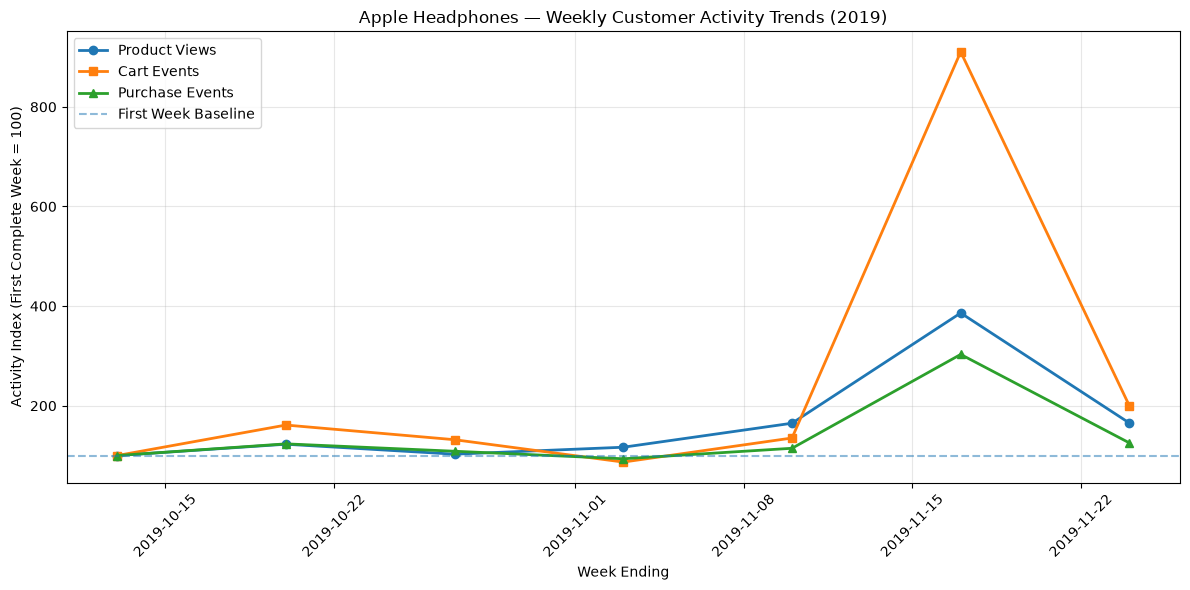

===== INDEXED WEEKLY CUSTOMER ACTIVITY =====


,Week_Ending,Views_Index,Cart_Events_Index,Purchases_Index
1,2019-10-13,100.00,100.00,100.00
2,2019-10-20,122.69,161.20,123.44
3,2019-10-27,102.72,131.75,108.59
4,2019-11-03,116.66,86.86,93.51
5,2019-11-10,164.86,135.17,114.54
6,2019-11-17,386.17,910.45,302.97
7,2019-11-24,165.23,199.77,125.32



===== PEAK CUSTOMER CART ACTIVITY =====
Week ending: 2019-11-17 00:00:00
Cart events: 48436
Purchase events: 11104
Product views: 289183


In [9]:

# STEP 9: VISUALIZE WEEKLY DEMAND-SENSING TRENDS


import pandas as pd
import matplotlib.pyplot as plt

# Use only complete 7-day weeks for fair comparisons
weekly_plot = (
    apple_weekly_complete
    .sort_values("Week_Ending")
    .copy()
)

# Select our three customer behavior indicators
metrics = ["Views", "Cart_Events", "Purchases"]

# Normalize each metric to 100 in the first complete week
for metric in metrics:

    baseline = weekly_plot[metric].iloc[0]

    weekly_plot[f"{metric}_Index"] = (
        weekly_plot[metric] / baseline
    ) * 100

# Create the chart
plt.figure(figsize=(12, 6))

plt.plot(
    weekly_plot["Week_Ending"],
    weekly_plot["Views_Index"],
    marker="o",
    linewidth=2,
    label="Product Views"
)

plt.plot(
    weekly_plot["Week_Ending"],
    weekly_plot["Cart_Events_Index"],
    marker="s",
    linewidth=2,
    label="Cart Events"
)

plt.plot(
    weekly_plot["Week_Ending"],
    weekly_plot["Purchases_Index"],
    marker="^",
    linewidth=2,
    label="Purchase Events"
)

# Add baseline reference line
plt.axhline(
    y=100,
    linestyle="--",
    alpha=0.5,
    label="First Week Baseline"
)

# Format the chart
plt.title(
    "Apple Headphones — Weekly Customer Activity Trends (2019)"
)

plt.xlabel("Week Ending")
plt.ylabel("Activity Index (First Complete Week = 100)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# Display weekly indexed activity
print("===== INDEXED WEEKLY CUSTOMER ACTIVITY =====")

display(
    weekly_plot[
        [
            "Week_Ending",
            "Views_Index",
            "Cart_Events_Index",
            "Purchases_Index"
        ]
    ].round({
        "Views_Index": 2,
        "Cart_Events_Index": 2,
        "Purchases_Index": 2
    })
)

# Identify the week with the highest cart activity
peak_week = weekly_plot.loc[
    weekly_plot["Cart_Events"].idxmax()
]

print("\n===== PEAK CUSTOMER CART ACTIVITY =====")

print("Week ending:", peak_week["Week_Ending"])
print("Cart events:", peak_week["Cart_Events"])
print("Purchase events:", peak_week["Purchases"])
print("Product views:", peak_week["Views"])


In [10]:

# STEP 10: INVESTIGATE NOVEMBER DEMAND SPIKE

import pandas as pd

# Examine the two weeks surrounding the spike
spike_analysis = apple_daily[
    apple_daily["Event_Date"].between(
        "2019-11-04",
        "2019-11-17"
    )
].copy()

# Calculate daily cart and purchase activity ratios
spike_analysis["Cart_to_View_Pct"] = (
    spike_analysis["Cart_Events"]
    / spike_analysis["Views"] * 100
)

spike_analysis["Purchase_to_View_Pct"] = (
    spike_analysis["Purchases"]
    / spike_analysis["Views"] * 100
)

print("===== DAILY CUSTOMER ACTIVITY =====")

display(
    spike_analysis[
        [
            "Event_Date",
            "Views",
            "Cart_Events",
            "Purchases",
            "Cart_to_View_Pct",
            "Purchase_to_View_Pct"
        ]
    ].round({
        "Cart_to_View_Pct": 2,
        "Purchase_to_View_Pct": 2
    })
)

# Compare the previous week against the spike week
metrics = ["Views", "Cart_Events", "Purchases"]

previous_week = spike_analysis[
    spike_analysis["Event_Date"] < "2019-11-11"
][metrics].sum()

spike_week = spike_analysis[
    spike_analysis["Event_Date"] >= "2019-11-11"
][metrics].sum()

# Create comparison table
spike_comparison = pd.DataFrame({
    "Previous_Week": previous_week,
    "Spike_Week": spike_week
})

spike_comparison["Percent_Change"] = (
    (
        spike_comparison["Spike_Week"]
        / spike_comparison["Previous_Week"]
    ) - 1
) * 100

print("\n===== WEEK-OVER-WEEK COMPARISON =====")

display(spike_comparison.round(2))

# Identify the day with the most cart activity
peak_cart_day = spike_analysis.loc[
    spike_analysis["Cart_Events"].idxmax()
]

print("\n===== HIGHEST CART ACTIVITY DAY =====")

print("Date:", peak_cart_day["Event_Date"])
print("Views:", peak_cart_day["Views"])
print("Cart events:", peak_cart_day["Cart_Events"])
print("Purchases:", peak_cart_day["Purchases"])
print(
    "Cart-to-view event ratio:",
    round(peak_cart_day["Cart_to_View_Pct"], 2),
    "%"
)


===== DAILY CUSTOMER ACTIVITY =====


,Event_Date,Views,Cart_Events,Purchases,Cart_to_View_Pct,Purchase_to_View_Pct
34,2019-11-04,20740,974,796,4.70,3.84
35,2019-11-05,18478,785,606,4.25,3.28
36,2019-11-06,17708,730,621,4.12,3.51
37,2019-11-07,17146,744,555,4.34,3.24
38,2019-11-08,16947,1530,618,9.03,3.65
39,2019-11-09,16124,1211,484,7.51,3.00
40,2019-11-10,16309,1217,518,7.46,3.18
41,2019-11-11,17529,1304,549,7.44,3.13
42,2019-11-12,17851,1236,465,6.92,2.60
43,2019-11-13,19919,1559,558,7.83,2.80



===== WEEK-OVER-WEEK COMPARISON =====


,Previous_Week,Spike_Week,Percent_Change
Views,123452,289183,134.25
Cart_Events,7191,48436,573.56
Purchases,4198,11104,164.51



===== HIGHEST CART ACTIVITY DAY =====
Date: 2019-11-15 00:00:00
Views: 62857
Cart events: 13509
Purchases: 0
Cart-to-view event ratio: 21.49 %


In [11]:
# STEP 11: VALIDATE NOVEMBER 15 PURCHASE ANOMALY

import duckdb

# Inspect purchase activity across the full November CSV
anomaly_validation = db.execute("""
    WITH daily_events AS (
        SELECT
            SUBSTR(event_time, 1, 10) AS Event_Date,
            event_type,
            category_code,
            LOWER(TRIM(brand)) AS brand

        FROM read_csv(
            ?,
            all_varchar = true,
            sample_size = 10000
        )

        WHERE SUBSTR(event_time, 1, 10)
              BETWEEN '2019-11-14' AND '2019-11-17'
    )

    SELECT
        Event_Date,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS All_Category_Purchases,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
              AND category_code =
                  'electronics.audio.headphone'
        ) AS All_Headphone_Purchases,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
              AND category_code =
                  'electronics.audio.headphone'
              AND brand = 'apple'
        ) AS Apple_Headphone_Purchases,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
              AND category_code =
                  'electronics.audio.headphone'
              AND brand = 'apple'
        ) AS Apple_Headphone_Views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
              AND category_code =
                  'electronics.audio.headphone'
              AND brand = 'apple'
        ) AS Apple_Headphone_Carts

    FROM daily_events

    GROUP BY Event_Date
    ORDER BY Event_Date
""", [str(nov_file)]).df()

print("===== NOVEMBER PURCHASE ANOMALY VALIDATION =====")

display(anomaly_validation)

# Isolate November 15
nov15 = anomaly_validation[
    anomaly_validation["Event_Date"] == "2019-11-15"
]

print("\n===== NOVEMBER 15 VALIDATION =====")

display(nov15)

print("\nTotal platform purchases on November 15:")
print(nov15["All_Category_Purchases"].iloc[0])

print("\nAll headphone purchases on November 15:")
print(nov15["All_Headphone_Purchases"].iloc[0])

print("\nApple headphone purchases on November 15:")
print(nov15["Apple_Headphone_Purchases"].iloc[0])


===== NOVEMBER PURCHASE ANOMALY VALIDATION =====


,Event_Date,All_Category_Purchases,All_Headphone_Purchases,Apple_Headphone_Purchases,Apple_Headphone_Views,Apple_Headphone_Carts
0,2019-11-14,22124,861,511,37954,5570
1,2019-11-15,0,0,0,62857,13509
2,2019-11-16,68247,3454,2685,71875,13194
3,2019-11-17,185195,8680,6336,61198,12064



===== NOVEMBER 15 VALIDATION =====


,Event_Date,All_Category_Purchases,All_Headphone_Purchases,Apple_Headphone_Purchases,Apple_Headphone_Views,Apple_Headphone_Carts
1,2019-11-15,0,0,0,62857,13509



Total platform purchases on November 15:
0

All headphone purchases on November 15:
0

Apple headphone purchases on November 15:
0


In [12]:

# STEP 12: FLAG SUSPECTED PURCHASE-DATA ANOMALY

import pandas as pd

# Preserve the original dataset
quality_daily = apple_daily.copy()

# Flag November 15 as a suspected data-quality issue
quality_daily["Purchase_Anomaly_Flag"] = (
    quality_daily["Event_Date"]
    == pd.Timestamp("2019-11-15")
)

# Create an analysis version of purchase counts
# Keep original purchases unchanged for auditing
quality_daily["Purchases_For_Analysis"] = (
    quality_daily["Purchases"].astype("Float64")
)

# Treat suspect purchase count as unknown, not genuine zero
quality_daily.loc[
    quality_daily["Purchase_Anomaly_Flag"],
    "Purchases_For_Analysis"
] = pd.NA

print("===== DAILY DATA QUALITY VALIDATION =====")

display(
    quality_daily.loc[
        quality_daily["Event_Date"].between(
            "2019-11-14", "2019-11-17"
        ),
        [
            "Event_Date",
            "Views",
            "Cart_Events",
            "Purchases",
            "Purchases_For_Analysis",
            "Purchase_Anomaly_Flag"
        ]
    ]
)

# Aggregate quality flags by reporting week
weekly_quality = (
    quality_daily
    .set_index("Event_Date")
    .resample("W-SUN")
    .agg(
        Days_Observed=("Views", "size"),
        Views=("Views", "sum"),
        Cart_Events=("Cart_Events", "sum"),
        Observed_Purchases=("Purchases", "sum"),
        Flagged_Days=("Purchase_Anomaly_Flag", "sum")
    )
    .reset_index()
    .rename(columns={"Event_Date": "Week_Ending"})
)

# Identify complete weeks without known purchase-data issues
weekly_quality["Usable_For_Purchase_Analysis"] = (
    (weekly_quality["Days_Observed"] == 7)
    & (weekly_quality["Flagged_Days"] == 0)
)

print("\n===== WEEKLY DATA QUALITY ASSESSMENT =====")

display(weekly_quality)

print("\n===== VALIDATION SUMMARY =====")

print(
    "Flagged daily records:",
    quality_daily["Purchase_Anomaly_Flag"].sum()
)

print(
    "Complete weeks usable for purchase analysis:",
    weekly_quality["Usable_For_Purchase_Analysis"].sum()
)

print(
    "Weeks excluded from purchase analysis:",
    (~weekly_quality["Usable_For_Purchase_Analysis"]).sum()
)


===== DAILY DATA QUALITY VALIDATION =====


,Event_Date,Views,Cart_Events,Purchases,Purchases_For_Analysis,Purchase_Anomaly_Flag
44,2019-11-14,37954,5570,511,511.0,False
45,2019-11-15,62857,13509,0,<NA>,True
46,2019-11-16,71875,13194,2685,2685.0,False
47,2019-11-17,61198,12064,6336,6336.0,False



===== WEEKLY DATA QUALITY ASSESSMENT =====


,Week_Ending,Days_Observed,Views,Cart_Events,Observed_Purchases,Flagged_Days,Usable_For_Purchase_Analysis
0,2019-10-06,6,65419,6314,3396,0,False
1,2019-10-13,7,74884,5320,3665,0,True
2,2019-10-20,7,91873,8576,4524,0,True
3,2019-10-27,7,76919,7009,3980,0,True
4,2019-11-03,7,87362,4621,3427,0,True
5,2019-11-10,7,123452,7191,4198,0,True
6,2019-11-17,7,289183,48436,11104,1,False
7,2019-11-24,7,123734,10628,4593,0,True
8,2019-12-01,6,125191,11271,4490,0,False



===== VALIDATION SUMMARY =====
Flagged daily records: 1
Complete weeks usable for purchase analysis: 6
Weeks excluded from purchase analysis: 3


In [13]:
# STEP 13: INVESTIGATE POST-ANOMALY PURCHASE SURGE

import pandas as pd

# Use dates before the unusual November 14-17 period
baseline_daily = quality_daily[
    quality_daily["Event_Date"] < "2019-11-14"
].copy()

# Calculate typical daily purchase activity
baseline_median = (
    baseline_daily["Purchases_For_Analysis"].median()
)

baseline_mean = (
    baseline_daily["Purchases_For_Analysis"].mean()
)

print("===== HISTORICAL PURCHASE BASELINE =====")

print("Baseline days:", len(baseline_daily))
print("Median daily purchases:", round(baseline_median, 2))
print("Average daily purchases:", round(baseline_mean, 2))

# Examine activity around the suspected anomaly
surge_analysis = quality_daily[
    quality_daily["Event_Date"].between(
        "2019-11-11", "2019-11-18"
    )
].copy()

# Compare daily purchase counts with the baseline
surge_analysis["Purchase_vs_Baseline"] = (
    surge_analysis["Purchases_For_Analysis"]
    / baseline_median
)

print("\n===== NOVEMBER SURGE ASSESSMENT =====")

display(
    surge_analysis[
        [
            "Event_Date",
            "Views",
            "Cart_Events",
            "Purchases",
            "Purchases_For_Analysis",
            "Purchase_Anomaly_Flag",
            "Purchase_vs_Baseline"
        ]
    ].round({
        "Purchase_vs_Baseline": 2
    })
)

# Find the highest recorded purchase days
top_purchase_days = (
    quality_daily
    .dropna(subset=["Purchases_For_Analysis"])
    .nlargest(10, "Purchases_For_Analysis")
)

print("\n===== TOP 10 RECORDED PURCHASE DAYS =====")

display(
    top_purchase_days[
        [
            "Event_Date",
            "Views",
            "Cart_Events",
            "Purchases_For_Analysis"
        ]
    ]
)


===== HISTORICAL PURCHASE BASELINE =====
Baseline days: 44
Median daily purchases: 540.5
Average daily purchases: 562.77

===== NOVEMBER SURGE ASSESSMENT =====


,Event_Date,Views,Cart_Events,Purchases,Purchases_For_Analysis,Purchase_Anomaly_Flag,Purchase_vs_Baseline
41,2019-11-11,17529,1304,549,549.0,False,1.02
42,2019-11-12,17851,1236,465,465.0,False,0.86
43,2019-11-13,19919,1559,558,558.0,False,1.03
44,2019-11-14,37954,5570,511,511.0,False,0.95
45,2019-11-15,62857,13509,0,<NA>,True,<NA>
46,2019-11-16,71875,13194,2685,2685.0,False,4.97
47,2019-11-17,61198,12064,6336,6336.0,False,11.72
48,2019-11-18,25171,2311,1003,1003.0,False,1.86



===== TOP 10 RECORDED PURCHASE DAYS =====


,Event_Date,Views,Cart_Events,Purchases_For_Analysis
47,2019-11-17,61198,12064,6336.0
46,2019-11-16,71875,13194,2685.0
59,2019-11-29,32083,2620,1038.0
48,2019-11-18,25171,2311,1003.0
15,2019-10-16,13887,1361,800.0
34,2019-11-04,20740,974,796.0
60,2019-11-30,22842,2143,780.0
58,2019-11-28,20471,1938,751.0
3,2019-10-04,13305,1655,739.0
16,2019-10-17,12666,1287,737.0


In [14]:
# STEP 14: EXPLORE LEADING DEMAND INDICATORS

import pandas as pd

# Preserve our quality-controlled daily dataset
lag_analysis = (
    quality_daily
    .sort_values("Event_Date")
    .copy()
)

# Flag the November 15-17 period for review
lag_analysis["Review_Flag"] = (
    lag_analysis["Event_Date"].between(
        "2019-11-15",
        "2019-11-17"
    )
)

# Create previous-day demand indicators
lag_analysis["Views_Lag_1"] = (
    lag_analysis["Views"].shift(1)
)

lag_analysis["Carts_Lag_1"] = (
    lag_analysis["Cart_Events"].shift(1)
)

# Flag observations where the prior day was suspect
lag_analysis["Prior_Day_Review"] = (
    lag_analysis["Review_Flag"].shift(
        1,
        fill_value=True
    )
)

# Exclude suspect target dates and prior-day inputs
valid_lag_data = lag_analysis[
    (~lag_analysis["Review_Flag"])
    & (~lag_analysis["Prior_Day_Review"])
].dropna(
    subset=[
        "Views_Lag_1",
        "Carts_Lag_1",
        "Purchases"
    ]
).copy()

print("===== LEADING INDICATOR DATASET =====")

print("Total original days:", len(lag_analysis))
print("Usable daily pairs:", len(valid_lag_data))

print("\n===== FIRST FIVE OBSERVATIONS =====")

display(
    valid_lag_data[
        [
            "Event_Date",
            "Views_Lag_1",
            "Carts_Lag_1",
            "Purchases"
        ]
    ].head()
)

# Calculate exploratory correlations
views_correlation = (
    valid_lag_data["Views_Lag_1"]
    .corr(valid_lag_data["Purchases"])
)

carts_correlation = (
    valid_lag_data["Carts_Lag_1"]
    .corr(valid_lag_data["Purchases"])
)

# Create a comparison table
correlation_results = pd.DataFrame({
    "Indicator": [
        "Previous-Day Views",
        "Previous-Day Cart Events"
    ],
    "Correlation_With_Next_Day_Purchases": [
        views_correlation,
        carts_correlation
    ]
})

print("\n===== LEADING INDICATOR CORRELATIONS =====")

display(
    correlation_results.round(3)
)

print("\n===== ANALYSIS COMPLETE =====")


===== LEADING INDICATOR DATASET =====
Total original days: 61
Usable daily pairs: 56

===== FIRST FIVE OBSERVATIONS =====


,Event_Date,Views_Lag_1,Carts_Lag_1,Purchases
1,2019-10-02,9878.0,757.0,529
2,2019-10-03,9734.0,699.0,531
3,2019-10-04,9786.0,705.0,739
4,2019-10-05,13305.0,1655.0,558
5,2019-10-06,11682.0,1379.0,495



===== LEADING INDICATOR CORRELATIONS =====


,Indicator,Correlation_With_Next_Day_Purchases
0,Previous-Day Views,0.442
1,Previous-Day Cart Events,0.470



===== ANALYSIS COMPLETE =====


In [15]:
# STEP 15: TEST DEMAND-SENSING FORECAST IMPROVEMENT

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create the previous day's purchase feature
lag_analysis["Purchases_Lag_1"] = (
    lag_analysis["Purchases_For_Analysis"].shift(1)
)

# Keep only valid observations and their prior-day inputs
model_data = (
    lag_analysis[
        (~lag_analysis["Review_Flag"])
        & (~lag_analysis["Prior_Day_Review"])
    ]
    .dropna(
        subset=[
            "Purchases_For_Analysis",
            "Purchases_Lag_1",
            "Views_Lag_1",
            "Carts_Lag_1"
        ]
    )
    .sort_values("Event_Date")
    .reset_index(drop=True)
    .copy()
)

# Target: current-day recorded purchase events
target = "Purchases_For_Analysis"

# Use chronological 70/30 train-test split
split_index = int(len(model_data) * 0.70)

train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()

print("===== TRAIN / TEST SPLIT =====")
print("Total usable observations:", len(model_data))
print("Training days:", len(train))
print("Testing days:", len(test))
print("First test date:", test["Event_Date"].min())
print("Last test date:", test["Event_Date"].max())

# MODEL 1: Naive forecast
naive_pred = test["Purchases_Lag_1"].to_numpy(dtype=float)

# MODEL 2: Ridge regression using purchasing history only
history_features = ["Purchases_Lag_1"]

history_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

history_model.fit(
    train[history_features],
    train[target].astype(float)
)

history_pred = history_model.predict(
    test[history_features]
)

# MODEL 3: Ridge regression with behavioral indicators
signal_features = [
    "Purchases_Lag_1",
    "Views_Lag_1",
    "Carts_Lag_1"
]

signal_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

signal_model.fit(
    train[signal_features],
    train[target].astype(float)
)

signal_pred = signal_model.predict(
    test[signal_features]
)

# Evaluate all three models
actual = test[target].to_numpy(dtype=float)

predictions = {
    "Naive Forecast": naive_pred,
    "Ridge - Purchase History": history_pred,
    "Ridge - Demand Signals": signal_pred
}

results = []

for model_name, forecast in predictions.items():

    error = forecast - actual

    mae = np.mean(np.abs(error))

    wape = (
        np.sum(np.abs(error))
        / np.sum(actual)
        * 100
    )

    bias = np.mean(error)

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "WAPE (%)": round(wape, 2),
        "Bias": round(bias, 2)
    })

model_comparison = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\n===== DEMAND-SENSING MODEL COMPARISON =====")
display(model_comparison)

# Show actual versus predicted purchases
forecast_comparison = test[
    ["Event_Date", target]
].copy()

forecast_comparison["Naive_Forecast"] = naive_pred
forecast_comparison["History_Forecast"] = history_pred
forecast_comparison["Signal_Forecast"] = signal_pred

print("\n===== ACTUAL VS FORECASTED PURCHASE EVENTS =====")

display(
    forecast_comparison.tail(10).round(2)
)


===== TRAIN / TEST SPLIT =====
Total usable observations: 56
Training days: 39
Testing days: 17
First test date: 2019-11-10 00:00:00
Last test date: 2019-11-30 00:00:00

===== DEMAND-SENSING MODEL COMPARISON =====


,Model,MAE,WAPE (%),Bias
0,Ridge - Purchase History,68.09,10.84,-36.83
1,Ridge - Demand Signals,71.20,11.33,-7.38
2,Naive Forecast,97.88,15.58,11.53



===== ACTUAL VS FORECASTED PURCHASE EVENTS =====


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_11693/2330510515.py:144: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  forecast_comparison.tail(10).round(2)


,Event_Date,Purchases_For_Analysis,Naive_Forecast,History_Forecast,Signal_Forecast
46,2019-11-21,627.0,605.0,579.64,611.65
47,2019-11-22,564.0,627.0,587.11,610.61
48,2019-11-23,520.0,564.0,565.71,579.97
49,2019-11-24,582.0,520.0,550.77,565.64
50,2019-11-25,583.0,582.0,571.83,581.20
51,2019-11-26,687.0,583.0,572.17,584.08
52,2019-11-27,651.0,687.0,607.49,627.28
53,2019-11-28,751.0,651.0,595.27,619.87
54,2019-11-29,1038.0,751.0,629.23,661.29
55,2019-11-30,780.0,1038.0,726.72,800.72


In [16]:

# STEP 16: EXPORT DEMAND-SENSING ANALYSIS RESULTS

from pathlib import Path
import pandas as pd

# Create processed output directory
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Combine weekly demand metrics with quality flags
weekly_export = apple_weekly.merge(
    weekly_quality[
        [
            "Week_Ending",
            "Flagged_Days",
            "Usable_For_Purchase_Analysis"
        ]
    ],
    on="Week_Ending",
    how="left",
    validate="one_to_one"
)

# Define export files
export_files = {
    "apple_headphones_daily_2019.csv": quality_daily,
    "apple_headphones_weekly_2019.csv": weekly_export,
    "demand_sensing_model_comparison_2019.csv": model_comparison,
    "demand_sensing_holdout_predictions_2019.csv": forecast_comparison
}

# Export each dataset
print("===== EXPORTING DEMAND-SENSING RESULTS =====")

for filename, dataframe in export_files.items():

    file_path = output_dir / filename

    dataframe.to_csv(
        file_path,
        index=False
    )

    print(f"Saved: {file_path}")
    print(f"Rows exported: {len(dataframe)}")
    print()

# Validate exported files
print("===== EXPORT VALIDATION =====")

for filename, original_df in export_files.items():

    file_path = output_dir / filename

    reloaded_df = pd.read_csv(file_path)

    assert len(reloaded_df) == len(original_df)

    print(
        f"{filename}: "
        f"{len(reloaded_df)} rows verified"
    )

print("\nAll demand-sensing files exported successfully!")


===== EXPORTING DEMAND-SENSING RESULTS =====
Saved: data/processed/apple_headphones_daily_2019.csv
Rows exported: 61

Saved: data/processed/apple_headphones_weekly_2019.csv
Rows exported: 9

Saved: data/processed/demand_sensing_model_comparison_2019.csv
Rows exported: 3

Saved: data/processed/demand_sensing_holdout_predictions_2019.csv
Rows exported: 17

===== EXPORT VALIDATION =====
apple_headphones_daily_2019.csv: 61 rows verified
apple_headphones_weekly_2019.csv: 9 rows verified
demand_sensing_model_comparison_2019.csv: 3 rows verified
demand_sensing_holdout_predictions_2019.csv: 17 rows verified

All demand-sensing files exported successfully!



## eCommerce Behavior — Findings and Methodology

### 1. Research Objective

Investigate whether customer browsing and shopping-cart
activity provides useful indicators for forecasting
consumer electronics purchases.

### 2. Dataset Overview

Source: Kaggle eCommerce Behavior Data (2019)

Files analyzed:
- 2019-Oct.csv — 5.67 GB
- 2019-Nov.csv — 9.01 GB

Selected segment:
- Apple-branded headphones
- October 1 – November 30, 2019

The dataset represents an independent eCommerce source
and is not directly equivalent to AirPods sales.

### 3. Data Processing

- Queried large raw CSV files using DuckDB.
- Filtered Apple headphone customer events.
- Aggregated activity into 61 daily observations.
- Created 9 weekly reporting periods.
- Calculated views, cart events, and purchase events.
- Validated record counts and calendar coverage.

### 4. Behavioral Demand Indicators

Total recorded events: 1,210,760

- Product views: 1,058,017
- Cart events: 109,366
- Purchase events: 43,377

These are recorded customer events, not necessarily
unique customers or physical units sold.

### 5. Data Quality Investigation

Identified an unusual event pattern during
November 15–17, 2019.

November 15 recorded zero purchases across the
eCommerce platform despite substantial customer
viewing and cart activity.

November 16 and 17 subsequently showed unusually
high purchase counts.

The underlying cause has not been established.

Preserved original observations and created
quality flags for exploratory analysis.

### 6. Leading Indicator Exploration

Analyzed 56 valid consecutive-day pairs.

Correlation with next-day purchases:

- Previous-day views: 0.442
- Previous-day cart events: 0.470

Both indicators demonstrated positive associations,
but correlation does not prove predictive value.

### 7. Forecasting Experiment

Compared three models using a chronological
training and testing split.

Results:

| Model | MAE | WAPE |
|---|---:|---:|
| Ridge - Purchase History | 68.09 | 10.84% |
| Ridge - Demand Signals | 71.20 | 11.33% |
| Naive Forecast | 97.88 | 15.58% |

The purchase-history Ridge model achieved the
lowest absolute forecasting error.

Adding behavioral features did not improve MAE
in this experiment, although it reduced bias.

### 8. Business Implications

- Customer activity provides useful descriptive
  information about purchasing behavior.
- Data-quality validation is essential before
  translating behavioral signals into forecasts.
- Additional variables should demonstrate
  incremental predictive value before adoption.
- Behavioral analytics may support monitoring
  and demand-planning research.

### 9. Limitations

- Only two months of historical data.
- Small forecasting holdout sample.
- Suspected purchase-recording anomalies.
- No demonstrated causal relationships.
- Independent retailer data cannot be directly
  treated as actual AirPods sales.
- No realized inventory savings have been measured.

### 10. Next Research Phase

Explore Global Electronics Retailers and Consumer
Electronics Purchase Intent datasets.

Assess opportunities for retail demand analysis,
customer segmentation, and additional forecasting
experiments.
